# Cel projektu
Celem projektu jest zaprojektowanie, zaimplementowanie oraz przetestowanie kompletnego potoku (pipeline) przetwarzania i rozpoznawania obrazów, umożliwiającego automatyczną identyfikację wybranych znaków drogowych. Projekt ma charakter praktyczny i jest realizowany w środowisku Jupyter Notebook z wykorzystaniem języka Python oraz bibliotek OpenCV, NumPy, Matplotlib, Scikit-image i Scikit-Learn.

W ramach projektu zostanie przygotowany zbiór danych zawierający co najmniej 100 oryginalnych zdjęć znaków drogowych, wykonanych w zróżnicowanych warunkach oświetlenia, odległości i orientacji. Oprócz trzech wybranych znaków zbiór będzie zawierał również inne znaki drogowe, co pozwoli ocenić zdolność systemu do odróżniania rozpoznawanych obiektów od pozostałych.

Opracowany system będzie obejmował kolejne etapy przetwarzania obrazu: wstępne przygotowanie danych, segmentację, ekstrakcję cech charakterystycznych oraz klasyfikację. Zakładanym celem jest osiągnięcie co najmniej 90% skuteczności rozpoznawania wybranych znaków drogowych na danych testowych.

Dysk google ze zdjęciami

https://drive.google.com/drive/folders/1qgMNpPgJHUDNbFQr3L3fJr9prOsZ97U5?usp=drive_link


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving 20261030_114458.jpg to 20261030_114458.jpg
Saving 20261030_115314.jpg to 20261030_115314.jpg
Saving 20261030_115838.jpg to 20261030_115838.jpg
Saving Blank diagram (1).png to Blank diagram (1) (1).png


# Wybór znaków
Wybieram do rozpoznania 3 znkai drogowe:

*   Znak stop B-20 (zakazu)
*   Znak ruch okrężny C-12 (nakazu)
*   Znak skrzyżowanie równorzędne (ostrzegawczy)


 # Analiza rozkładu jasności i kolorów znaków drogowych

W celu analizy kolorystycznej wybranych znaków drogowych wykorzystano przestrzeń barwną HSV, która pozwala na oddzielną analizę odcienia (H), nasycenia (S) oraz jasności (V).

**Znaki zakazu**


Histogram odcienia (H) wskazuje na dominację koloru czerwonego, występującego w okolicach wartości 0 oraz 175. Wysokie wartości nasycenia (S) wskazują na intensywną barwę czerwonego tła. Histogram jasności (V) pokazuje duże skupienie pikseli w okolicy wartości 125.

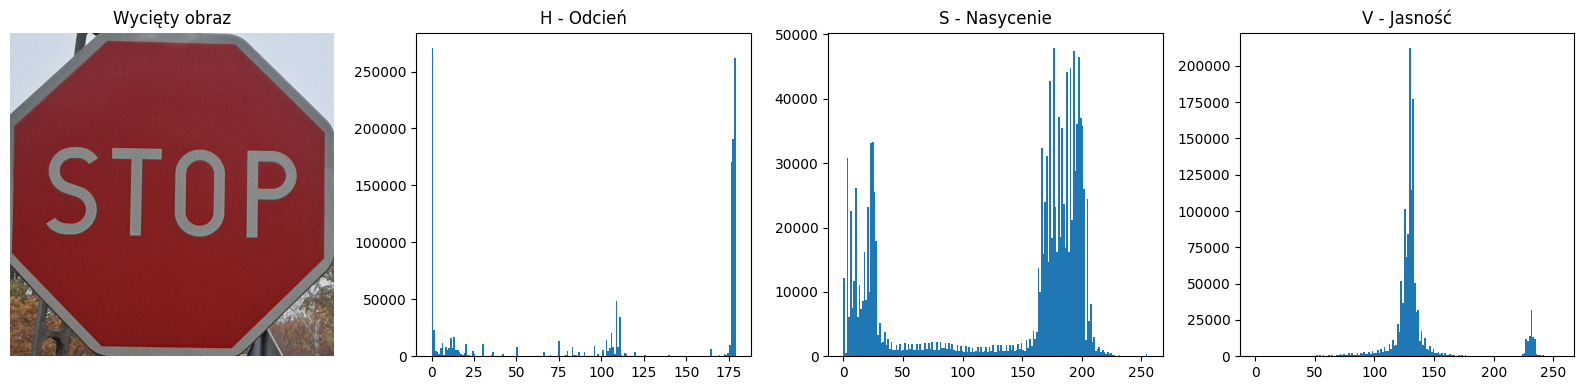

In [ ]:
import cv2
import matplotlib.pyplot as plt

img_original_prohibitory = cv2.imread("20261030_115314.jpg")
img_prohibitory = img_original_prohibitory[2950:4100,2400:3550]

rgb = cv2.cvtColor(img_prohibitory, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(img_prohibitory, cv2.COLOR_BGR2HSV)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(rgb)
ax[0].set_title("Wycięty obraz")
ax[0].axis("off")

for i, nazwa in enumerate(["H - Odcień", "S - Nasycenie", "V - Jasność"]):
    ax[i+1].hist(hsv[:,:,i].ravel(), bins=180)
    ax[i+1].set_title(nazwa)

plt.tight_layout()
plt.show()

**Znaki Nakazu**

Histogram odcienia (H) charakteryzuje się wyraźnym maksimum w okolicy wartości 105–110, odpowiadających kolorowi niebieskiemu. W kanale S występuje bardzo wysoki poziom nasycenia, szczególnie dla niebieskiego tła znaku. Histogram jasności (V) wskazuje na obecność zarówno ciemniejszych obszarów niebieskich, jak i jaśniejszych elementów symbolu.

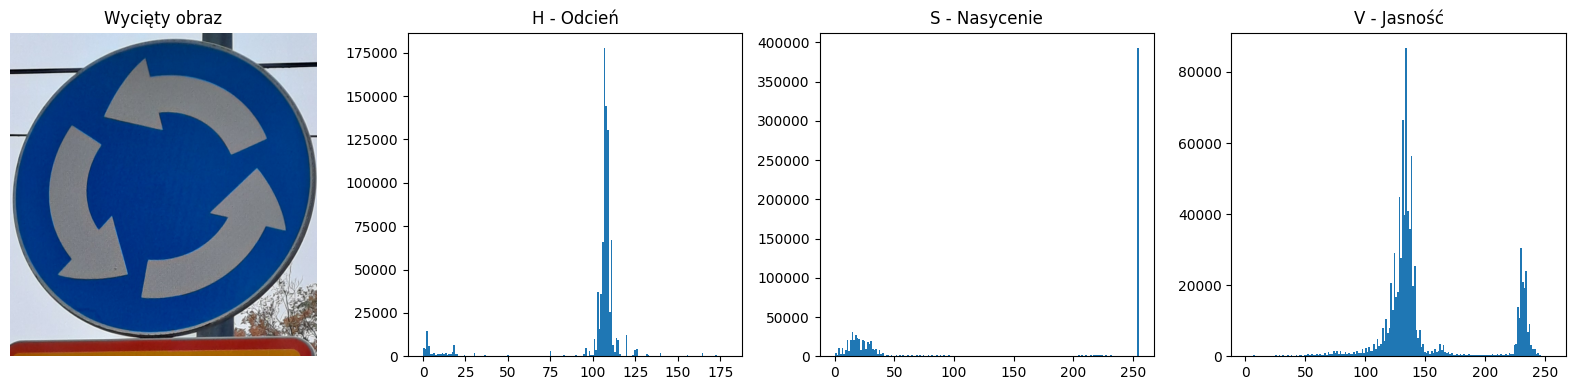

In [ ]:
img_original_mandatory = cv2.imread("20261030_115838.jpg")
img_mandatory = img_original_mandatory[3000:3950,2500:3400]

rgb = cv2.cvtColor(img_mandatory, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(img_mandatory, cv2.COLOR_BGR2HSV)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(rgb)
ax[0].set_title("Wycięty obraz")
ax[0].axis("off")

for i, nazwa in enumerate(["H - Odcień", "S - Nasycenie", "V - Jasność"]):
    ax[i+1].hist(hsv[:,:,i].ravel(), bins=180)
    ax[i+1].set_title(nazwa)

plt.tight_layout()

**Znaki ostrzegawcze**

Histogram odcienia (H) wskazuje na duży udział kolorów żółto-pomarańczowych w okolicy wartości 15–20. Widoczne jest również czerwone obramowanie znaku. Wysokie wartości nasycenia (S) odpowiadają intensywnym kolorom znaku. Histogram jasności (V) wykazuje wyraźne maksimum w okolicy wartości 150–160.

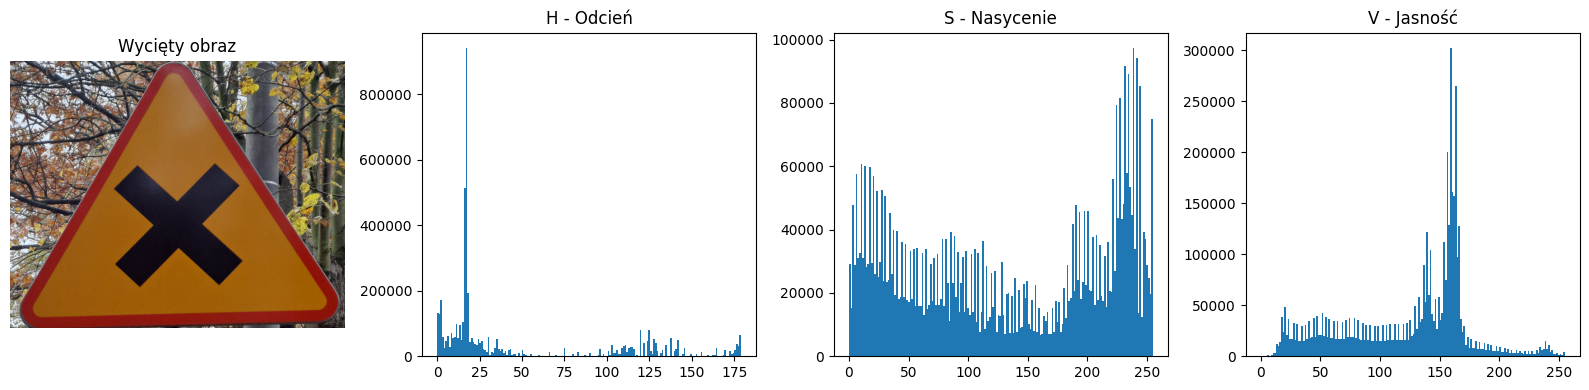

In [ ]:
img_original_warning = cv2.imread("20261030_114458.jpg")
img_warning = img_original_warning[1800:3800,1700:4200]

rgb = cv2.cvtColor(img_warning, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(img_warning, cv2.COLOR_BGR2HSV)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(rgb)
ax[0].set_title("Wycięty obraz")
ax[0].axis("off")

for i, nazwa in enumerate(["H - Odcień", "S - Nasycenie", "V - Jasność"]):
    ax[i+1].hist(hsv[:,:,i].ravel(), bins=180)
    ax[i+1].set_title(nazwa)

plt.tight_layout()

# **Projekt schematu przetwarzania (flowchart)**

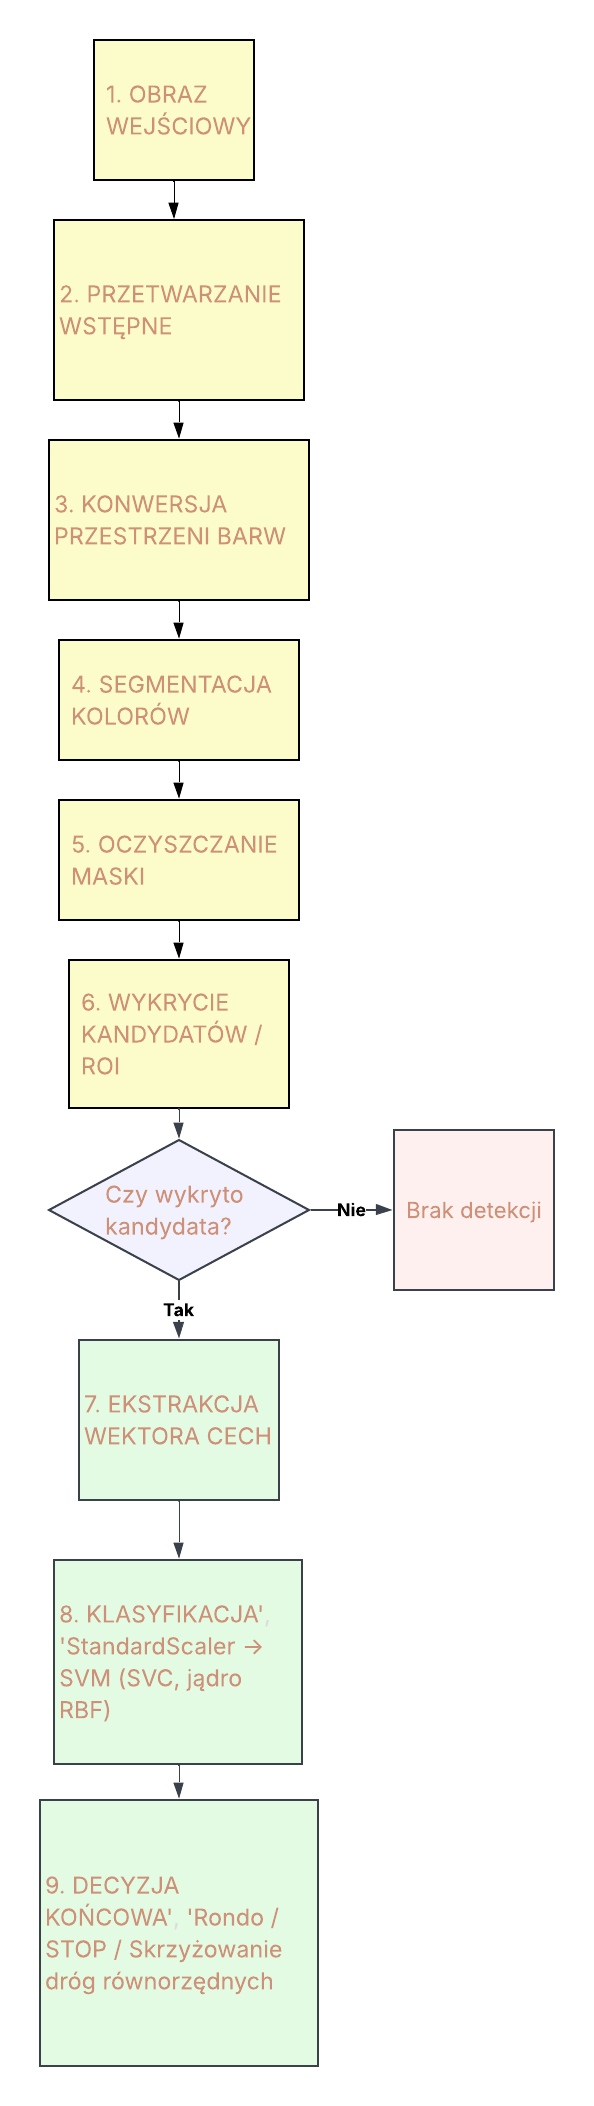

In [ ]:
from IPython.display import display, Image

display(Image(filename="Blank diagram (1).png"))

### 1. Obraz wejściowy

**Metoda:** Wczytanie obrazu za pomocą `cv2.imread()`.

### 2. Przetwarzanie wstępne
**Metody:**
- Skalowanie proporcjonalne – `cv2.resize()`.
- Filtr Gaussa 5×5 – `cv2.GaussianBlur()`.
- Opcjonalnie CLAHE – `cv2.createCLAHE()`.

**Uzasadnienie:** Skalowanie zmniejsza koszt obliczeniowy przy zachowaniu proporcji obrazu. Filtr Gaussa redukuje szumy i drobne zakłócenia, ułatwiając późniejszą segmentację. CLAHE pozwala poprawić lokalny kontrast zdjęć wykonanych w trudnych warunkach oświetleniowych.

### 3. Konwersja przestrzeni barw
**Metoda:** Konwersja BGR → HSV za pomocą `cv2.cvtColor()`.

**Uzasadnienie:** Przestrzeń HSV oddziela informację o odcieniu koloru od jego nasycenia i jasności. Ułatwia to wykrywanie charakterystycznych kolorów znaków drogowych: czerwonego, niebieskiego i żółtego.

### 4. Segmentacja kolorów
**Metoda:** Progowanie kolorów w HSV za pomocą `cv2.inRange()`.

**Uzasadnienie:** Metoda umożliwia wyodrębnienie pikseli należących do określonych zakresów kolorystycznych. Pozwala utworzyć maski binarne wskazujące obszary potencjalnie zawierające znaki drogowe. Dla koloru czerwonego stosowane będą dwa zakresy wartości H ze względu na jego położenie na granicach skali OpenCV.

### 5. Oczyszczanie maski
**Metody:**
- Otwarcie morfologiczne 3×3.
- Zamknięcie morfologiczne 5×5.
- Funkcja `cv2.morphologyEx()`.

**Uzasadnienie:** Otwarcie usuwa drobne zakłócenia z maski binarnej. Zamknięcie wypełnia niewielkie przerwy i otwory w wykrytych obszarach. Operacje te poprawiają jakość maski przed analizą konturów.

### 6. Wykrywanie kandydatów / ROI
**Metody:**
- `cv2.findContours()` – wykrywanie konturów.
- `cv2.contourArea()` – analiza powierzchni.
- `cv2.approxPolyDP()` – przybliżenie kształtu konturu.
- `cv2.boundingRect()` – wyznaczenie obszaru ROI.

**Uzasadnienie:** Analiza konturów pozwala odnaleźć potencjalne znaki drogowe na podstawie ich wielkości i geometrii. Filtrowanie kandydatów umożliwia odrzucenie części elementów tła, a wyznaczenie ROI pozwala ograniczyć dalszą analizę do wykrytego obszaru.

### 7. Ekstrakcja cech
**Metody:**
- Cechy geometryczne: zwartość, liczba wierzchołków, proporcja szerokości do wysokości.
- Siedem momentów Hu – `cv2.HuMoments()`.
- Cechy kolorystyczne: udział pikseli czerwonych, niebieskich i żółtych.

**Uzasadnienie:** Cechy geometryczne opisują kształt znaku, natomiast momenty Hu dostarczają informacji o geometrii w dużym stopniu niezależnej od przesunięcia, skalowania i obrotu. Cechy kolorystyczne pozwalają dodatkowo rozróżniać znaki na podstawie dominujących barw. Łącznie otrzymujemy 13-elementowy wektor cech.

### 8. Klasyfikacja
**Metody:**
- Standaryzacja cech – `StandardScaler`.
- Klasyfikator SVM z jądrem RBF – `SVC(kernel='rbf')`.

**Uzasadnienie:** Standaryzacja ujednolica skalę wartości poszczególnych cech, ograniczając wpływ ich różnych zakresów liczbowych. SVM z jądrem RBF umożliwia wyznaczanie nieliniowych granic decyzyjnych i dobrze nadaje się do klasyfikacji na podstawie niewielkich wektorów cech.

### 9. Decyzja końcowa
**Metoda:** Przypisanie obiektu do klasy na podstawie wyniku `predict()` klasyfikatora SVM.

**Uzasadnienie:** Klasyfikator na podstawie wyodrębnionych cech podejmuje decyzję o przynależności wykrytego znaku do jednej z trzech klas: C-12 (rondo), B-20 (STOP) lub A-5 (skrzyżowanie dróg równorzędnych).

W przypadku niewykrycia odpowiedniego kandydata system zwraca komunikat „Brak detekcji”. Dodatkowo planuje się odrzucanie obiektów nienależących do rozpoznawanych klas.